# 02 · Modelado y evaluación — Momento 3
**Proyecto:** Producción frutícola del Valle del Cauca 2000–2022 · Carlos Ignacio Grueso P. · Jean Carlos Cárdenas
**Fuente:** datos.gov.co — Ministerio de Agricultura, Evaluaciones Agropecuarias Municipales (descarga 28-sep-2026).

## Plantilla de los 4 puntos (Clase 13)
1. **Definición operativa:** pronosticar cuántas toneladas dará un cultivo en un municipio **dentro de 3 años**, para que la Secretaría de Agricultura fije metas del plan de fomento y mida su efecto.
2. **Tipificación:** **regresión**, porque la variable objetivo (toneladas) es numérica continua.
3. **Evaluación honesta:** partición 80/20 con `random_state=42` *antes* de cualquier ajuste; métricas sobre el conjunto de prueba; Gap train–test; comparación contra el modelo tonto (`DummyRegressor`) y contra una regla simple.
4. **Interpretabilidad:** importancia de variables por permutación y lectura para el negocio.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
from preparacion import limpiar
from modelo import construir_tabla, COLS, NOMBRES, HORIZONTE
SEMILLA = 42

## 1. Datos limpios
La limpieza vive en `preparacion.py` (texto a número, 39 duplicados eliminados, 0 vacíos, 202 ceros conservados).

In [2]:
d, log = limpiar('frutales.csv')
log

{'filas_originales': 9992,
 'celdas_vacias': 0,
 'duplicados_eliminados': 39,
 'registros_en_cero': 202,
 'filas_finales': 9953}

## 2. Tabla de modelado
Una fila por municipio–cultivo–año. Para pronosticar el año *t* solo se usa información conocida en *t−3* (cosechas de hace 3, 4 y 5 años, tendencias), así **no hay fuga de datos**.

In [3]:
t = construir_tabla(d)
X, y = t[COLS], t['Produccion_toneladas']
print(len(t), 'filas'); t.head()

7477 filas


,Municipio,Subregion,Cultivo,anio,Produccion_toneladas,prod_hace_3,prod_hace_4,prod_hace_5,tendencia_local,tendencia_depto
3,Alcalá,Norte,Aguacate,2003,123.0,60.0,60.0,60.0,0.0,1.000000
4,Alcalá,Norte,Aguacate,2004,176.0,60.0,60.0,60.0,0.0,1.000000
5,Alcalá,Norte,Aguacate,2005,198.0,60.0,60.0,60.0,0.0,1.299686
6,Alcalá,Norte,Aguacate,2006,198.0,123.0,60.0,60.0,63.0,1.066321
7,Alcalá,Norte,Aguacate,2007,358.0,176.0,123.0,60.0,116.0,1.073742


## 3. Partición 80/20 (antes de cualquier ajuste)

In [4]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=SEMILLA)
print('Entrenamiento:', len(Xtr), '· Prueba:', len(Xte))

Entrenamiento: 5981 · Prueba: 1496


## 4. Líneas base
- **Modelo tonto:** siempre predice el promedio del entrenamiento.
- **Regla simple:** repetir la última cosecha conocida (la de hace 3 años).

In [5]:
tonto = DummyRegressor(strategy='mean').fit(Xtr, ytr)
res = {'Modelo tonto (promedio)': mean_absolute_error(yte, tonto.predict(Xte)),
       'Regla simple (repetir última cosecha)': mean_absolute_error(yte, Xte['prod_hace_3'])}
res

{'Modelo tonto (promedio)': 2687.550253359083,
 'Regla simple (repetir última cosecha)': 978.8196423796792}

## 5. Modelo A · Árbol de decisión
El árbol necesita columnas numéricas: se codifican municipio, cultivo y subregión con *one-hot* (no hay escalado ni imputación).

In [6]:
Xtr_d = pd.get_dummies(Xtr, dtype=int); Xte_d = pd.get_dummies(Xte, dtype=int).reindex(columns=Xtr_d.columns, fill_value=0)
curva_arbol = []
for p in range(1, 11):
    m = DecisionTreeRegressor(max_depth=p, min_samples_leaf=20, random_state=SEMILLA).fit(Xtr_d, ytr)
    curva_arbol.append((p, r2_score(ytr, m.predict(Xtr_d)), r2_score(yte, m.predict(Xte_d)), mean_absolute_error(yte, m.predict(Xte_d))))
curva_arbol = pd.DataFrame(curva_arbol, columns=['profundidad', 'R2_train', 'R2_test', 'MAE_test']); curva_arbol['Gap'] = curva_arbol.R2_train - curva_arbol.R2_test
curva_arbol.round(3)

,profundidad,R2_train,R2_test,MAE_test,Gap
0,1,0.528,0.604,1761.747,-0.076
1,2,0.659,0.684,1250.738,-0.025
2,3,0.706,0.721,1021.087,-0.015
3,4,0.726,0.744,928.484,-0.019
4,5,0.735,0.744,925.653,-0.009
5,6,0.740,0.749,905.550,-0.009
6,7,0.743,0.749,913.485,-0.006
7,8,0.744,0.750,914.775,-0.006
8,9,0.744,0.750,904.462,-0.006
9,10,0.744,0.750,909.557,-0.006


In [7]:
ok = curva_arbol[curva_arbol.Gap <= 0.10]
p_arbol = int(ok.loc[ok.MAE_test.idxmin(), 'profundidad'])
arbol = DecisionTreeRegressor(max_depth=p_arbol, min_samples_leaf=20, random_state=SEMILLA).fit(Xtr_d, ytr)
res[f'Árbol de decisión (profundidad {p_arbol})'] = mean_absolute_error(yte, arbol.predict(Xte_d))
print('Profundidad elegida:', p_arbol)

Profundidad elegida: 9


## 6. Modelo B · Árboles en cadena (HistGradientBoosting)
Muchos árboles pequeños; cada uno corrige el error del anterior. Maneja municipio y cultivo como categorías.

In [8]:
def gb(p): return HistGradientBoostingRegressor(loss='absolute_error', max_depth=p, learning_rate=0.05, max_iter=400,
                                            categorical_features='from_dtype', random_state=SEMILLA)
curva_gb = []
for p in range(1, 9):
    m = gb(p).fit(Xtr, ytr)
    curva_gb.append((p, r2_score(ytr, m.predict(Xtr)), r2_score(yte, m.predict(Xte)), mean_absolute_error(yte, m.predict(Xte))))
curva_gb = pd.DataFrame(curva_gb, columns=['profundidad', 'R2_train', 'R2_test', 'MAE_test']); curva_gb['Gap'] = curva_gb.R2_train - curva_gb.R2_test
curva_gb.round(3)

,profundidad,R2_train,R2_test,MAE_test,Gap
0,1,0.660,0.716,884.026,-0.055
1,2,0.694,0.720,837.854,-0.026
2,3,0.708,0.727,824.932,-0.019
3,4,0.730,0.752,782.845,-0.022
4,5,0.739,0.743,769.614,-0.003
5,6,0.761,0.746,783.249,0.015
6,7,0.733,0.742,784.771,-0.009
7,8,0.733,0.743,787.298,-0.010


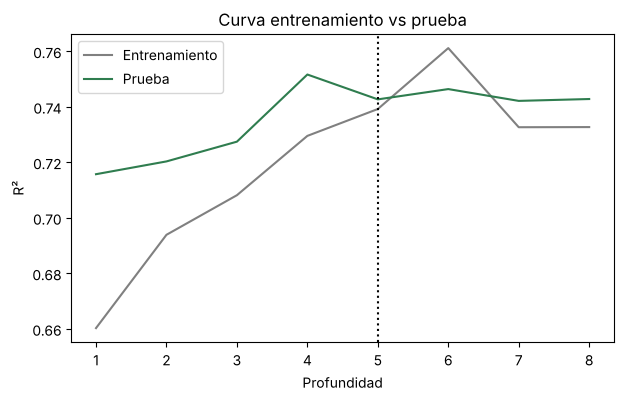

In [9]:
ok = curva_gb[curva_gb.Gap <= 0.10]
p_gb = int(ok.loc[ok.MAE_test.idxmin(), 'profundidad'])
modelo = gb(p_gb).fit(Xtr, ytr)
res[f'Árboles en cadena (profundidad {p_gb})'] = mean_absolute_error(yte, modelo.predict(Xte))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(curva_gb.profundidad, curva_gb.R2_train, label='Entrenamiento', color='grey'); ax.plot(curva_gb.profundidad, curva_gb.R2_test, label='Prueba', color='#2f7d4f')
ax.axvline(p_gb, ls=':', color='k'); ax.set_xlabel('Profundidad'); ax.set_ylabel('R²'); ax.set_title('Curva entrenamiento vs prueba'); ax.legend(); plt.show()

## 7. Comparación final (conjunto de prueba)

In [10]:
comp = pd.Series(res).sort_values().rename('MAE en prueba (t)').to_frame()
comp['Mejora vs regla simple %'] = (1 - comp.iloc[:, 0] / res['Regla simple (repetir última cosecha)']) * 100
print('R² train', round(r2_score(ytr, modelo.predict(Xtr)), 3), '· R² test', round(r2_score(yte, modelo.predict(Xte)), 3),
      '· Gap', round(r2_score(ytr, modelo.predict(Xtr)) - r2_score(yte, modelo.predict(Xte)), 3))
comp.round(1)

R² train 0.739 · R² test 0.743 · Gap -0.003


,MAE en prueba (t),Mejora vs regla simple %
Árboles en cadena (profundidad 5),769.6,21.4
Árbol de decisión (profundidad 9),904.5,7.6
Regla simple (repetir última cosecha),978.8,0.0
Modelo tonto (promedio),2687.6,-174.6


## 8. Prueba en el tiempo (más exigente)
Entrenar con años ≤ 2019 y pronosticar 2020–2022.

In [11]:
tr, te = t.anio <= 2019, t.anio >= 2020
mt = gb(p_gb).fit(X[tr], y[tr])
print('Modelo:', round(mean_absolute_error(y[te], mt.predict(X[te]))), 't · Regla simple:', round(mean_absolute_error(y[te], X['prod_hace_3'][te])), 't')

Modelo: 684 t · Regla simple: 708 t


## 9. Interpretabilidad · importancia por permutación

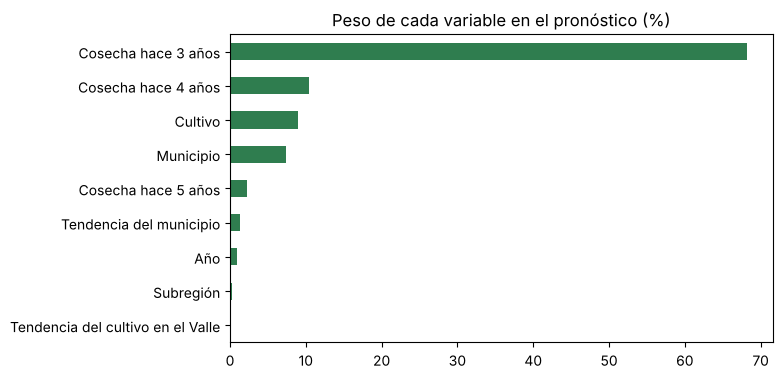

In [12]:
pi = permutation_importance(modelo, Xte, yte, n_repeats=5, random_state=SEMILLA, scoring='neg_mean_absolute_error')
imp = pd.Series(np.clip(pi.importances_mean, 0, None), index=COLS); imp = (imp / imp.sum() * 100).rename(NOMBRES).sort_values()
imp.plot.barh(color='#2f7d4f', figsize=(7, 4), title='Peso de cada variable en el pronóstico (%)'); plt.show()

## 10. Pronóstico 2025 sin plan de fomento (aguacate, mango, papaya, lulo)

In [13]:
from modelo import pronosticar
pr = pronosticar()
print('Valle:', pr[['prod_hace_3', 'pronostico']].sum().round(0).to_dict())
print('Sur:  ', pr[pr.Subregion == 'Sur'][['prod_hace_3', 'pronostico']].sum().round(0).to_dict())
pr.groupby('Cultivo')[['prod_hace_3', 'pronostico']].sum().round(0)

Valle: {'prod_hace_3': 66845.0, 'pronostico': 59868.0}
Sur:   {'prod_hace_3': 12873.0, 'pronostico': 12120.0}


,prod_hace_3,pronostico
Cultivo,,
Aguacate,30737.0,27392.0
Lulo,16817.0,16474.0
Mango,4007.0,3589.0
Papaya,15284.0,12413.0


## 11. Agrupamiento de municipios (no supervisado · K-Means, k=3)
Variables escaladas: tamaño (log), crecimiento y peso de los 4 cultivos.

In [14]:
from modelo import agrupar_municipios
g = agrupar_municipios()
display(g.groupby('perfil').agg(municipios=('total', 'size'), crecimiento=('crecimiento_%', 'median'), peso_4=('peso_4_cultivos_%', 'median')).round(1))
for p, s in g.groupby('perfil'): print(p, ':', ', '.join(s.index))

,municipios,crecimiento,peso_4
perfil,,,
"Crecen rápido, poca diversificación",14,242.4,4.2
Estancados,19,17.2,5.4
Ya apuestan a los 4 cultivos,9,43.7,24.6


Crecen rápido, poca diversificación : Alcalá, Argelia, Caicedonia, Dagua, El Aguila, El Cairo, Jamundí, La Cumbre, Restrepo, Riofrío, Sevilla, Trujillo, Vijes, Yotoco
Estancados : Ansermanuevo, Bolivar, Buenaventura, Buga, Bugalagrande, Cali, Candelaria, Cartago, El Cerrito, Florida, Ginebra, La Victoria, Obando, Palmira, Pradera, Toro, Ulloa, Versalles, Zarzal
Ya apuestan a los 4 cultivos : Andalucia, Calima Darién, El Dovio, Guacarí, La Unión, Roldanillo, San Pedro, Tuluá, Yumbo


## 12. Conclusiones
- El modelo de árboles en cadena es el elegido: menor error en prueba, Gap ≤ 0,10 y supera al modelo tonto y a la regla simple.
- La variable dominante es la cosecha conocida más reciente; cultivo y municipio también aportan.
- Sin intervención, los 4 cultivos en ascenso bajarían cerca de 10% al 2025 → respalda el plan de fomento.
- **Límite:** en 2020–2022 (pandemia) la ventaja sobre la regla simple es pequeña. Pronosticar no es explicar causas.